# Part 2: fewer blank counties

Start from the Part 1 layer and fill blank values from two sources, **never overwriting an FHFA county figure**:

1. **Connecticut crosswalk**: in the old release, FHFA reports the 8 pre-2022 counties while the map uses the 9 planning regions. Each region gets a housing-unit-weighted average of the old counties its towns came from.
2. **ZIP-based estimates**: a housing-unit-weighted average of FHFA's ZIP-level values for ZIPs overlapping the county, used only when ZIPs with data cover **≥ 50% of the county's homes**.

We deliberately skip filling from neighbouring counties: it would manufacture the spatial clusters Part 4 asks about.

New columns: `yoy_source` / `cagr_source` (`fhfa`, `ct_crosswalk`, `zip`, or null) and `coverage` (share of the county's homes behind an estimate).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import part1

pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
CENSUS = DATA_DIR / "census"
RELEASE_DIR = DATA_DIR / "fhfa" / "next_release"   # DATA_DIR / "fhfa" is the older release (ends 2024)

MIN_COVERAGE = 0.5
METRICS = {"hpi_yoy_pct": "yoy_source", "hpi_cagr_5y_pct": "cagr_source"}

## Step 1: The Part 1 layer and the FHFA county metrics

In [2]:
base, L = part1.build_layer(RELEASE_DIR)
hpi = part1.read_fhfa_county(RELEASE_DIR / "hpi_at_county.xlsx")
county_metrics = part1.compute_metrics(hpi, L)   # includes FHFA codes not on the map (e.g. old CT counties)

blank_before = base[list(METRICS)].isna()
print("blank yoy:", blank_before.hpi_yoy_pct.sum(), "| blank cagr:", blank_before.hpi_cagr_5y_pct.sum(),
      "| both blank:", blank_before.all(axis=1).sum())

C:\Projects\data-eng-assessment-055\data\fhfa\next_release (released 2026-03-31): latest year 2025, 3144 counties


blank yoy: 532 | blank cagr: 470 | both blank: 469


## Step 2: Housing units (the weights)

The ACS file holds every geography; the first 3 characters of `GEO_ID` are the summary level. We need three:
`050` county, `060` county subdivision (Connecticut towns), `860` ZCTA.

In [3]:
def read_housing_units() -> dict[str, pd.Series]:
    acs = pd.read_csv(CENSUS / "acsdt5y2024-b25001.dat", sep="|", dtype=str, usecols=["GEO_ID", "B25001_E001"])
    level = acs.GEO_ID.str[:3]
    code = acs.GEO_ID.str.split("US").str[1]
    units = pd.to_numeric(acs.B25001_E001)
    return {lvl: pd.Series(units[level == lvl].values, index=code[level == lvl].values) for lvl in ("050", "060", "860")}


hu = read_housing_units()
print({lvl: len(s) for lvl, s in hu.items()})

{'050': 3222, '060': 36421, '860': 33772}


## Step 3: Connecticut, old counties → planning regions

The crosswalk lists every town with its old county and its new region. Towns are also an ACS geography, so we know how many homes each one has. A region's value is then

> Σ over old counties ( value of old county × homes in the towns it contributes ) ÷ Σ homes

These are real counts, not a land-area guess. The same coverage rule applies: the old counties with a value must account for ≥ 50% of the region's homes.

In [4]:
def read_ct_crosswalk() -> pd.DataFrame:
    ct = pd.read_excel(CENSUS / "ct_cou_to_cousub_crosswalk.xlsx", dtype=str)
    ct.columns = [c.splitlines()[0] for c in ct.columns]
    ct = ct.dropna(subset=["STATEFP", "COUSUBFP"])   # empty rows at the bottom of the sheet
    ct = ct[ct.COUSUBFP != "00000"]                   # 'County subdivisions not defined' (water) placeholders
    return pd.DataFrame({
        "old_county": ct.STATEFP + ct.OLD_COUNTYFP,
        "new_county": ct.STATEFP + ct.NEW_COUNTYFP,
        "town": ct.STATEFP + ct.NEW_COUNTYFP + ct.COUSUBFP,   # rebuilt: the GEOID columns are Excel formulas
        "town_name": ct.COUSUB_NAMELSAD,
    })


xwalk = read_ct_crosswalk()
xwalk["units"] = xwalk.town.map(hu["060"])
print("towns:", len(xwalk), "| regions:", xwalk.new_county.nunique(), "| old counties:", xwalk.old_county.nunique())
assert xwalk.units.notna().all(), "every town should have ACS housing units"
xwalk.head()

towns: 169 | regions: 9 | old counties: 8


,old_county,new_county,town,town_name,units
0,09001,09120,0912008070,Bridgeport town,59844
1,09001,09120,0912023890,Easton town,2606
2,09001,09120,0912026620,Fairfield town,22537
3,09001,09120,0912048620,Monroe town,6589
4,09001,09120,0912074190,Stratford town,21663


In [5]:
def weighted_estimates(pieces: pd.DataFrame, values: pd.DataFrame, key: str, target: str,
                       target_units: pd.Series) -> pd.DataFrame:
    """Housing-unit-weighted mean of `values` (indexed by key) for each target area.

    pieces: one row per (key, target) overlap with its `units`.
    Returns one row per target: an estimate per metric (null below MIN_COVERAGE) and its coverage.
    """
    out = {}
    for col in METRICS:
        p = pieces.join(values[col], on=key).dropna(subset=[col, "units"])
        p = p[p.units > 0]
        covered = p.groupby(target).units.sum()
        est = (p[col] * p.units).groupby(p[target]).sum() / covered
        cov = (covered / target_units.reindex(covered.index)).clip(upper=1)
        out[col] = est.where(cov >= MIN_COVERAGE)
        out[col.replace("hpi_", "cov_")] = cov
    return pd.DataFrame(out)


ct_units = xwalk.groupby("new_county").units.sum()
ct_est = weighted_estimates(xwalk, county_metrics, "old_county", "new_county", ct_units)
print("CT regions estimable from old counties in this release:", ct_est.hpi_yoy_pct.notna().sum())
ct_est

CT regions estimable from old counties in this release: 0


,hpi_yoy_pct,cov_yoy_pct,hpi_cagr_5y_pct,cov_cagr_5y_pct
new_county,,,,


With the next release this table is empty: FHFA already publishes the 9 regions and has no old-county codes, so there is nothing to translate. The crosswalk matters for the **old** release. Let's run it there and check it against the regions FHFA publishes for the same year in the next release:

In [6]:
old_dir = DATA_DIR / "fhfa"
old_hpi = part1.read_fhfa_county(old_dir / "hpi_at_county.xlsx")
old_L = part1.latest_year(old_hpi)
old_ct = weighted_estimates(xwalk, part1.compute_metrics(old_hpi, old_L), "old_county", "new_county", ct_units)

# the next release publishes the regions directly; compute the same metrics for the same year
truth = part1.compute_metrics(hpi, old_L)
cmp_ct = old_ct[["hpi_yoy_pct", "hpi_cagr_5y_pct"]].join(
    truth[["hpi_yoy_pct", "hpi_cagr_5y_pct"]].add_suffix("_fhfa_next"))
cmp_ct["yoy_err"] = cmp_ct.hpi_yoy_pct - cmp_ct.hpi_yoy_pct_fhfa_next
cmp_ct["cagr_err"] = cmp_ct.hpi_cagr_5y_pct - cmp_ct.hpi_cagr_5y_pct_fhfa_next
print(f"old release, year {old_L}: crosswalk estimate vs FHFA's own region figure in the next release")
cmp_ct.round(2)

old release, year 2024: crosswalk estimate vs FHFA's own region figure in the next release


,hpi_yoy_pct,hpi_cagr_5y_pct,hpi_yoy_pct_fhfa_next,hpi_cagr_5y_pct_fhfa_next,yoy_err,cagr_err
new_county,,,,,,
09110,9.89,9.49,9.74,9.45,0.15,0.05
09120,7.32,8.97,7.35,9.77,-0.03,-0.79
09130,8.52,9.42,8.71,9.42,-0.19,-0.00
09140,8.01,9.63,7.67,10.07,0.34,-0.44
09150,9.12,9.73,9.01,9.73,0.11,0.00
09160,7.52,10.05,8.43,10.28,-0.91,-0.23
09170,7.84,9.64,7.32,9.34,0.52,0.29
09180,7.13,9.77,7.11,9.95,0.02,-0.18
09190,7.32,9.03,7.38,8.54,-0.06,0.49


In [7]:
print("mean |error| yoy: %.2f pt | cagr: %.2f pt" % (cmp_ct.yoy_err.abs().mean(), cmp_ct.cagr_err.abs().mean()))

mean |error| yoy: 0.26 pt | cagr: 0.28 pt


Part of that gap is FHFA's own revision between releases, not the crosswalk; we saw earlier that 2023–24 growth was revised by a median of ~0.65 pt.

## Step 4: ZIP-level metrics

Same years L, L-1, L-5 from the **same release's** ZIP file, using the same exact-year rule as counties.

In [8]:
def read_zip_metrics(release_dir: Path, latest: int) -> pd.DataFrame:
    zips = pd.read_excel(release_dir / "hpi_at_zip5.xlsx", skiprows=5, usecols=range(6),
                         dtype={"Five-Digit ZIP Code": str})
    zips = zips.rename(columns={"Five-Digit ZIP Code": "fips", "Year": "year", "HPI": "hpi"})[["fips", "year", "hpi"]]
    m = part1.compute_metrics(zips, latest)   # 'fips' here holds ZIP codes; same exact-year logic
    m.index.name = "zcta"
    return m


zip_metrics = read_zip_metrics(RELEASE_DIR, L)
print("ZIPs:", len(zip_metrics), "| with yoy:", zip_metrics.hpi_yoy_pct.notna().sum(),
      "| with cagr:", zip_metrics.hpi_cagr_5y_pct.notna().sum())

ZIPs: 19024 | with yoy: 14731 | with cagr: 15742


## Step 5: ZCTA × county pieces and their homes

The ACS counts homes per whole ZCTA. We spread them over the ZCTA's land:
`units in piece ≈ ZCTA homes × piece land ÷ ZCTA land`.

**Guard:** if a piece would hold more homes than its entire county, the land assumption has clearly failed (a city ZCTA with a long empty tail into a rural county, as with El Paso → Hudspeth). We drop that piece.

In [9]:
def read_zcta_pieces(zcta_units: pd.Series, county_units: pd.Series) -> pd.DataFrame:
    rel = pd.read_csv(CENSUS / "tab20_zcta520_county20_natl.txt", sep="|", dtype=str, encoding="utf-8-sig")
    rel = rel.dropna(subset=["GEOID_ZCTA5_20"])
    p = pd.DataFrame({
        "zcta": rel.GEOID_ZCTA5_20,
        "county": rel.GEOID_COUNTY_20,
        "land_share": pd.to_numeric(rel.AREALAND_PART) / pd.to_numeric(rel.AREALAND_ZCTA5_20),
    })
    p["units"] = p.zcta.map(zcta_units) * p.land_share
    p["misallocated"] = p.units > p.county.map(county_units)
    return p


pieces_all = read_zcta_pieces(hu["860"], hu["050"])
print("pieces:", len(pieces_all), "| dropped as misallocated:", pieces_all.misallocated.sum(),
      "| without ACS homes:", pieces_all.units.isna().sum())
pieces_all[pieces_all.misallocated].assign(county_units=lambda d: d.county.map(hu["050"])).head(8).round(2)

pieces: 46960 | dropped as misallocated: 62 | without ACS homes: 22


,zcta,county,land_share,units,misallocated,county_units
925,00624,72111,0.95,8910.32,True,8789
970,00674,72091,0.99,19493.86,True,19464
997,00693,72145,0.98,27147.37,True,27010
1018,00719,72105,0.97,11460.03,True,11460
1033,00729,72029,0.92,19256.19,True,18667
1040,00736,72035,0.92,20805.77,True,20583
1048,00745,72119,1.00,23591.10,True,23376
1057,00767,72151,0.99,14707.20,True,14631


In [10]:
pieces = pieces_all[~pieces_all.misallocated]
zip_est = weighted_estimates(pieces, zip_metrics, "zcta", "county", hu["050"])
print("counties with a ZIP estimate (>= 50% coverage): yoy", zip_est.hpi_yoy_pct.notna().sum(),
      "| cagr", zip_est.hpi_cagr_5y_pct.notna().sum())

counties with a ZIP estimate (>= 50% coverage): yoy 2204 | cagr 2304


## Step 6: Back-test, how good are ZIP estimates?

For counties FHFA **does** publish we can compare the ZIP estimate with FHFA's own county figure. The coverage threshold should be where the error becomes acceptable.

In [11]:
pieces_any = pieces.copy()
saved = MIN_COVERAGE
MIN_COVERAGE = 0.0          # estimate everything, then bin by coverage
est_any = weighted_estimates(pieces_any, zip_metrics, "zcta", "county", hu["050"])
MIN_COVERAGE = saved

pub = base.set_index("geoid")
rows = []
for col in METRICS:
    cov_col = col.replace("hpi_", "cov_")
    d = est_any[[col, cov_col]].join(pub[col].rename(col + "_fhfa"), how="inner").dropna()
    d["abs_err"] = (d[col] - d[col + "_fhfa"]).abs()
    d["coverage_bin"] = pd.cut(d[cov_col], [0, .25, .5, .75, 1.0], include_lowest=True)
    t = d.groupby("coverage_bin", observed=True).abs_err.agg(counties="size", median_abs_err="median",
                                                             p90_abs_err=lambda s: s.quantile(.9))
    rows.append(t.assign(metric=col))
backtest = pd.concat(rows).reset_index().set_index(["metric", "coverage_bin"]).round(2)
backtest

counties  median_abs_err  p90_abs_err
metric          coverage_bin                                         
hpi_yoy_pct     (-0.001, 0.25]       115            6.72        24.33
                (0.25, 0.5]          222            3.25         9.44
                (0.5, 0.75]          602            1.84         6.37
                (0.75, 1.0]         1572            0.71         3.03
hpi_cagr_5y_pct (-0.001, 0.25]       116            1.20         4.01
                (0.25, 0.5]          200            0.61         2.16
                (0.5, 0.75]          595            0.34         1.15
                (0.75, 1.0]         1682            0.17         0.66

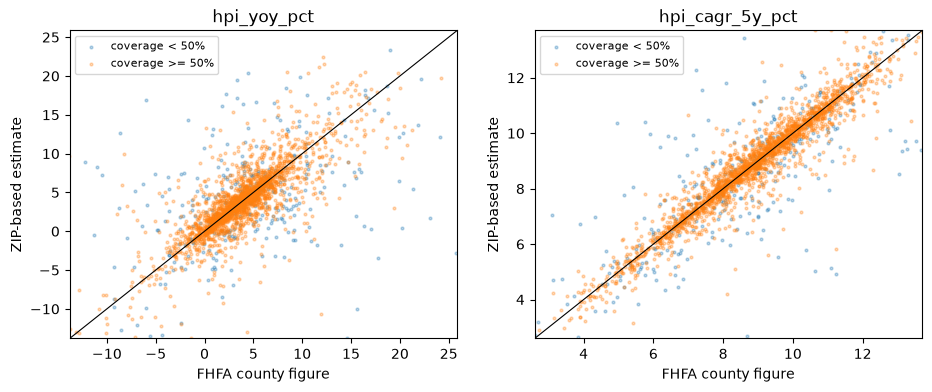

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, METRICS):
    cov_col = col.replace("hpi_", "cov_")
    d = est_any[[col, cov_col]].join(pub[col].rename(col + "_fhfa"), how="inner").dropna()
    hi = d[d[cov_col] >= MIN_COVERAGE]
    lo = d[d[cov_col] < MIN_COVERAGE]
    ax.scatter(lo[col + "_fhfa"], lo[col], s=4, alpha=.3, label=f"coverage < {MIN_COVERAGE:.0%}")
    ax.scatter(hi[col + "_fhfa"], hi[col], s=4, alpha=.3, label=f"coverage >= {MIN_COVERAGE:.0%}")
    lim = [d[col + "_fhfa"].quantile(.005), d[col + "_fhfa"].quantile(.995)]
    ax.plot(lim, lim, color="k", lw=.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("FHFA county figure"); ax.set_ylabel("ZIP-based estimate"); ax.set_title(col); ax.legend(fontsize=8)

Read the table with care: published counties are the well-measured ones, so blank counties will usually do somewhat worse than this. YoY is much noisier than the 5-year CAGR because one year of a small sample moves a lot.

## Step 7: Fill the layer

Order of preference per value: FHFA → CT crosswalk → ZIP. A county keeps its Part 1 status unless something was filled:
- `estimated_ct_crosswalk`: at least one value from the Connecticut crosswalk
- `estimated_zip`: at least one value from ZIPs (the other may still be FHFA's; see `yoy_source` / `cagr_source`)

In [13]:
def fill_layer(base: pd.DataFrame, estimates: list[tuple[str, pd.DataFrame]]) -> pd.DataFrame:
    out = base.copy()
    out["coverage"] = np.nan
    for col, src in METRICS.items():
        out[src] = np.where(out[col].notna(), "fhfa", None)
        cov_col = col.replace("hpi_", "cov_")
        for name, est in estimates:
            value = out.geoid.map(est[col]).astype(float)   # an empty estimate table maps to object dtype
            take = out[col].isna() & value.notna()
            out.loc[take, col] = value[take]
            out.loc[take, src] = name
            # coverage of the weakest estimate in the row
            cov = out.geoid.map(est[cov_col]).astype(float)
            out.loc[take, "coverage"] = np.fmin(out.loc[take, "coverage"], cov[take])
    sources = out[list(METRICS.values())]
    out.loc[(sources == "zip").any(axis=1), "status"] = "estimated_zip"
    out.loc[(sources == "ct_crosswalk").any(axis=1), "status"] = "estimated_ct_crosswalk"
    cols = ["geoid", "name", "state", "hpi_yoy_pct", "hpi_cagr_5y_pct", "status",
            "yoy_source", "cagr_source", "coverage", "geometry"]
    return out[cols]


layer = fill_layer(base, [("ct_crosswalk", ct_est), ("zip", zip_est)])

# FHFA values are untouched
kept = base[list(METRICS)].notna()
for col in METRICS:
    assert (layer.loc[kept[col], col] == base.loc[kept[col], col]).all()
assert (layer.loc[base.status == "published", "status"] == "published").all()

blank_after = layer[list(METRICS)].isna()
pd.DataFrame({"before (Part 1)": blank_before.sum(), "after (Part 2)": blank_after.sum()}).rename_axis("blank values")

,before (Part 1),after (Part 2)
blank values,,
hpi_yoy_pct,532,502
hpi_cagr_5y_pct,470,443


In [14]:
layer.status.value_counts().rename("counties").to_frame()

,counties
status,
published,2611
not_in_fhfa,330
no_latest,110
partial_no_yoy,59
estimated_zip,31
no_prior_years,2
partial_no_cagr,1


In [15]:
pd.crosstab(layer.yoy_source.fillna("none"), layer.cagr_source.fillna("none"), margins=True)

cagr_source,fhfa,none,zip,All
yoy_source,,,,
fhfa,2611,1,0,2612
none,59,442,1,502
zip,4,0,26,30
All,2674,443,27,3144


In [16]:
layer[layer.status.str.startswith("estimated")].drop(columns="geometry").sort_values("coverage").head(10).round(2)

,geoid,name,state,hpi_yoy_pct,hpi_cagr_5y_pct,status,yoy_source,cagr_source,coverage
1634,30069,Petroleum County,MT,1.07,8.81,estimated_zip,zip,zip,0.51
250,08011,Bent County,CO,1.25,12.13,estimated_zip,zip,fhfa,0.52
1939,37095,Hyde County,NC,-5.60,9.66,estimated_zip,zip,fhfa,0.54
300,08109,Saguache County,CO,7.05,10.90,estimated_zip,zip,zip,0.55
342,12043,Glades County,FL,2.78,11.24,estimated_zip,zip,zip,0.57
1434,28063,Jefferson County,MS,6.71,5.52,estimated_zip,zip,zip,0.58
1423,28041,Greene County,MS,NaN,6.39,estimated_zip,NaN,zip,0.59
2683,48317,Martin County,TX,0.85,5.22,estimated_zip,zip,zip,0.60
1458,28111,Perry County,MS,-7.68,6.98,estimated_zip,zip,fhfa,0.60
1658,31005,Arthur County,NE,3.62,7.72,estimated_zip,zip,zip,0.62


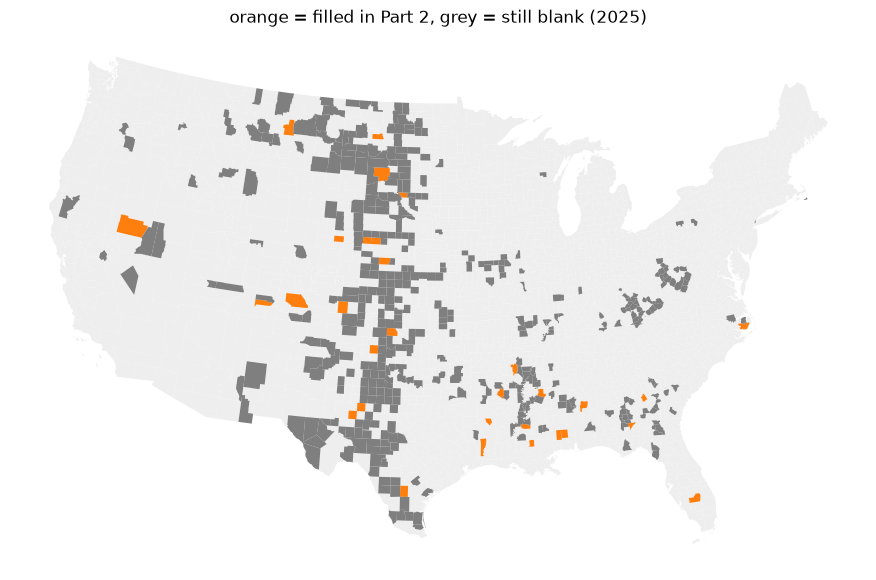

In [17]:
lower48 = layer[~layer.state.isin(["AK", "HI"])].to_crs(5070)
ax = lower48.plot(color="#eee", linewidth=0, figsize=(12, 7))
lower48[lower48.status.str.startswith("estimated")].plot(ax=ax, color="tab:orange")
lower48[lower48.hpi_yoy_pct.isna() & lower48.hpi_cagr_5y_pct.isna()].plot(ax=ax, color="tab:grey")
ax.set_axis_off(); ax.set_title(f"orange = filled in Part 2, grey = still blank ({L})");

## Step 8: Report for both releases, status before and after each fill

The same pipeline for the old release (latest year 2024) and the next release (2025), with the status counts after each stage:
1. **Part 1**: FHFA county figures only
2. **+ CT crosswalk**: Connecticut regions from old-county figures
3. **+ ZIP**: ZIP-based estimates with ≥ 50% coverage

In [18]:
def fill_stages(release_dir: Path) -> tuple[int, dict[str, pd.DataFrame]]:
    base, latest = part1.build_layer(release_dir)
    cm = part1.compute_metrics(part1.read_fhfa_county(release_dir / "hpi_at_county.xlsx"), latest)
    ct = weighted_estimates(xwalk, cm, "old_county", "new_county", ct_units)
    zp = weighted_estimates(pieces, read_zip_metrics(release_dir, latest), "zcta", "county", hu["050"])
    return latest, {
        "1 Part 1": base,
        "2 + CT crosswalk": fill_layer(base, [("ct_crosswalk", ct)]),
        "3 + ZIP": fill_layer(base, [("ct_crosswalk", ct), ("zip", zp)]),
    }


runs = {}
for release_dir in (DATA_DIR / "fhfa", DATA_DIR / "fhfa" / "next_release"):
    year, stages = fill_stages(release_dir)
    runs[year] = stages

FHFA counties with no 2024 boundary (not on the map): ['09001', '09003', '09005', '09007', '09009', '09011', '09013', '09015']
C:\Projects\data-eng-assessment-055\data\fhfa (released 2025-03-25): latest year 2024, 3144 counties


C:\Projects\data-eng-assessment-055\data\fhfa\next_release (released 2026-03-31): latest year 2025, 3144 counties


In [19]:
STATUS_ORDER = ["published", "estimated_ct_crosswalk", "estimated_zip", "partial_no_yoy", "partial_no_cagr",
                "no_prior_years", "no_latest", "not_in_fhfa"]

status_report = pd.concat(
    {(year, stage): df.status.value_counts() for year, stages in runs.items() for stage, df in stages.items()},
    axis=1).reindex(STATUS_ORDER).fillna(0).astype(int)
status_report.columns.names = ["latest year", "stage"]
status_report.loc["total"] = status_report.sum()
status_report

latest year                2024                              2025                         
stage                  1 Part 1 2 + CT crosswalk 3 + ZIP 1 Part 1 2 + CT crosswalk 3 + ZIP
status                                                                                    
published                  2543             2543    2543     2611             2611    2611
estimated_ct_crosswalk        0                9       9        0                0       0
estimated_zip                 0                0      37        0                0      31
partial_no_yoy               76               76      73       63               63      59
partial_no_cagr               2                2       2        1                1       1
no_prior_years                4                4       4        2                2       2
no_latest                   154              154     142      118              118     110
not_in_fhfa                 365              356     334      349              349     330
total                      3144             3144    3144     3144             3144    3144

In [20]:
blank_report = pd.concat(
    {(year, stage): pd.Series({
        "blank hpi_yoy_pct": df.hpi_yoy_pct.isna().sum(),
        "blank hpi_cagr_5y_pct": df.hpi_cagr_5y_pct.isna().sum(),
        "both blank": (df.hpi_yoy_pct.isna() & df.hpi_cagr_5y_pct.isna()).sum(),
        "at least one value": (df.hpi_yoy_pct.notna() | df.hpi_cagr_5y_pct.notna()).sum(),
    }) for year, stages in runs.items() for stage, df in stages.items()}, axis=1)
blank_report.columns.names = ["latest year", "stage"]
blank_report

latest year               2024                              2025                         
stage                 1 Part 1 2 + CT crosswalk 3 + ZIP 1 Part 1 2 + CT crosswalk 3 + ZIP
blank hpi_yoy_pct          599              590     560      532              532     502
blank hpi_cagr_5y_pct      525              516     482      470              470     443
both blank                 523              514     480      469              469     442
at least one value        2621             2630    2664     2675             2675    2702

### Where did each Part 1 status go?

Rows are the Part 1 status and columns the final status after both fills. Off-diagonal cells are counties a fill method changed.

In [21]:
for year, stages in runs.items():
    before = stages["1 Part 1"].status.rename("Part 1 status")
    after = stages["3 + ZIP"].status.rename("final status")
    t = pd.crosstab(before, after, margins=True, margins_name="total")
    print(f"latest year {year}")
    display(t)

latest year 2024


final status,estimated_ct_crosswalk,estimated_zip,no_latest,no_prior_years,not_in_fhfa,partial_no_cagr,partial_no_yoy,published,total
Part 1 status,,,,,,,,,
no_latest,0,12,142,0,0,0,0,0,154
no_prior_years,0,0,0,4,0,0,0,0,4
not_in_fhfa,9,22,0,0,334,0,0,0,365
partial_no_cagr,0,0,0,0,0,2,0,0,2
partial_no_yoy,0,3,0,0,0,0,73,0,76
published,0,0,0,0,0,0,0,2543,2543
total,9,37,142,4,334,2,73,2543,3144


latest year 2025


final status,estimated_zip,no_latest,no_prior_years,not_in_fhfa,partial_no_cagr,partial_no_yoy,published,total
Part 1 status,,,,,,,,
no_latest,8,110,0,0,0,0,0,118
no_prior_years,0,0,2,0,0,0,0,2
not_in_fhfa,19,0,0,330,0,0,0,349
partial_no_cagr,0,0,0,0,1,0,0,1
partial_no_yoy,4,0,0,0,0,59,0,63
published,0,0,0,0,0,0,2611,2611
total,31,110,2,330,1,59,2611,3144


In [22]:
# The CT regions in each release, end to end
pd.concat({year: stages["3 + ZIP"].query("state == 'CT'").set_index("geoid")[
    ["name", "hpi_yoy_pct", "hpi_cagr_5y_pct", "status", "coverage"]] for year, stages in runs.items()}).round(2)

name  hpi_yoy_pct  hpi_cagr_5y_pct                  status  coverage
     geoid                                                                                                                
2024 09110                         Capitol Planning Region         9.89             9.49  estimated_ct_crosswalk       1.0
     09120              Greater Bridgeport Planning Region         7.32             8.97  estimated_ct_crosswalk       1.0
     09130  Lower Connecticut River Valley Planning Region         8.52             9.42  estimated_ct_crosswalk       1.0
     09140                Naugatuck Valley Planning Region         8.01             9.63  estimated_ct_crosswalk       1.0
     09150        Northeastern Connecticut Planning Region         9.12             9.73  estimated_ct_crosswalk       1.0
     09160                 Northwest Hills Planning Region         7.52            10.05  estimated_ct_crosswalk       1.0
     09170       South Central Connecticut Planning Region         7.84             9.64  estimated_ct_crosswalk       1.0
     09180        Southeastern Connecticut Planning Region         7.13             9.77  estimated_ct_crosswalk       1.0
     09190             Western Connecticut Planning Region         7.32             9.03  estimated_ct_crosswalk       1.0
2025 09110                         Capitol Planning Region         5.74            10.07               published       NaN
     09120              Greater Bridgeport Planning Region         5.75            10.39               published       NaN
     09130  Lower Connecticut River Valley Planning Region         5.59             9.90               published       NaN
     09140                Naugatuck Valley Planning Region         6.41            10.52               published       NaN
     09150        Northeastern Connecticut Planning Region         6.63            10.11               published       NaN
     09160                 Northwest Hills Planning Region         6.82            10.51               published       NaN
     09170       South Central Connecticut Planning Region         6.31             9.98               published       NaN
     09180        Southeastern Connecticut Planning Region         7.46            10.58               published       NaN
     09190             Western Connecticut Planning Region         5.83             9.33               published       NaN

## Step 9: Write and test

In [23]:
part1.write_outputs(layer)
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-500:], r.stderr[-500:])

wrote counties.parquet and counties.geojson (6.73 MB)


....                                                                     [100%]
4 passed in 1.06s
 


## Decisions to carry into `NOTES.md`

- **Never overwrite FHFA.** Estimates fill only blank values; `yoy_source` / `cagr_source` say where each value came from.
- **Connecticut (old release)**: region = housing-unit-weighted average of its old counties, with weights from ACS town-level homes. The error vs FHFA's own region figures in the next release is shown in Step 3.
- **ZIP estimates**: housing-unit-weighted mean of ZIP growth rates (not index levels, which have different base years). Pieces that would hold more homes than their whole county are dropped. Values are filled only when ZIPs with data cover ≥ 50% of the county's homes; the back-test in Step 6 shows the error by coverage.
- **Not done**: neighbour-based filling, which would create the spatial clusters Part 4 measures.
- **What remains blank** are mostly counties with few sales, whose ZIPs have no index either. That is a limit of the data, not of the method.